<font color = LightBlue Size  = 10>Fatemeh Mohammadi  
 SID: 810199489  
 HW1</font>

# <font color = lightGreen> Problem 1: 
 Food Recommendation System  </font>

## <font> Setup </font>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
from scipy.stats import beta

In [2]:
SID = 810199489

num_arms = ((SID) % 100) % 5 + 2
probabilities = [int(digit)/10 for digit in str(SID)[-num_arms:]]

print(f"Num arms: {num_arms}")
print(f"Probabilities: {probabilities}")

Num arms: 6
Probabilities: [0.1, 0.9, 0.9, 0.4, 0.8, 0.9]


## <font> Simulation Function </font>

In [3]:
num_trials = 50
num_rounds = 1000

In [4]:
def compute_confidence_intervals(data, confidence=0.95):
    mean = np.mean(data, axis=0)
    std_err = np.std(data, axis=0) / np.sqrt(len(data))
    h = std_err * 1.96  # for 95% confidence interval
    return mean, h

In [5]:

def simulate(algorithm_class, probabilities, num_arms, num_rounds, num_trials=1, compute_confidence=True, **kwargs):
    rewards_all_trials = np.zeros((num_trials, num_rounds))
    regrets_all_trials = np.zeros((num_trials, num_rounds))
    max_expected_reward = np.max(probabilities)

    optimal_selections_all_trials = np.zeros((num_trials, num_rounds))



    for trial in range(num_trials):
        algorithm = algorithm_class(num_arms, **kwargs)
        rewards = np.zeros(num_rounds)
        regrets = np.zeros(num_rounds)
        optimal_selections = np.zeros(num_rounds)

        for round_i in range(num_rounds):
            arm = algorithm.select_arm()
            reward = 1 if random.random() < probabilities[arm] else 0
            algorithm.update(arm, reward)

            rewards[round_i] = reward
            regrets[round_i] = max_expected_reward - probabilities[arm]
            optimal_selections[round_i] = 1 if probabilities[arm] == max_expected_reward else 0  # Record optimal selection

        rewards_all_trials[trial] = np.cumsum(rewards)
        regrets_all_trials[trial] = np.cumsum(regrets)
        optimal_selections_all_trials[trial] = optimal_selections  # Save optimal selections for this trial


    results = {}

    if num_trials > 1 and compute_confidence:
        rewards_mean, rewards_conf = compute_confidence_intervals(rewards_all_trials)
        regrets_mean, regrets_conf = compute_confidence_intervals(regrets_all_trials)

        results['rewards_mean'] = rewards_mean
        results['rewards_conf_interval'] = rewards_conf
        results['regrets_mean'] = regrets_mean
        results['regrets_conf_interval'] = regrets_conf
    else:
        results['rewards'] = rewards_all_trials[0]
        results['regrets'] = regrets_all_trials[0]

    results['optimal_selections'] = np.mean(optimal_selections_all_trials, axis=0) if num_trials > 1 else optimal_selections_all_trials[0]

    return results


## <font>Thompson Sampling Algorithm </font>

In [6]:
class thompson_sampling:
    def __init__(self, num_arms, initial_alpha=1, initial_beta=1):

        self.num_arms = num_arms
        self.alpha = np.ones(num_arms) * initial_alpha
        self.beta = np.ones(num_arms) * initial_beta


    def select_arm(self):
        samples = [beta.rvs(self.alpha[i], self.beta[i]) for i in range(self.num_arms)]
        return np.argmax(samples)

    def update(self, arm, reward):
        self.alpha[arm] += reward
        self.beta[arm] += (1 - reward)

## <font> Upper Confidence Bound (UCB) Algorithm </font>

In [7]:
UCB_C = 1

class UCB:
    def __init__(self, num_arms, c = UCB_C):
        self.num_arms = num_arms
        self.c = c
        self.t = 0
        self.counts = np.zeros(num_arms)
        self.means = np.zeros(num_arms)
        self.UCBs = [float('inf') for _ in range(num_arms)]

    def select_arm(self):
        # print(self.UCBs)
        if self.t < self.num_arms:
            return self.t
        else:
            return np.argmax(self.UCBs)

    def update(self, arm, reward):
        self.t += 1

        self.counts[arm] += 1
        self.means[arm] += (reward - self.means[arm]) / self.counts[arm]
        self.UCBs[arm] = self.means[arm] + self.c * np.sqrt(np.log(self.t) / self.counts[arm])

## <font> Epsilon-Greedy Algorithm </font>

In [8]:
class epsilon_greedy:
    def __init__(self, num_arms, initial_epsilon=1.0, min_epsilon=0.01, decay_rate=0.99):
        self.num_arms = num_arms
        self.min_epsilon = min_epsilon
        self.epsilon = initial_epsilon
        self.decay_rate = decay_rate
        self.counts = np.zeros(num_arms)
        self.means = np.zeros(num_arms)
        self.q_values = np.zeros(num_arms)

    def select_arm(self):
        if random.random() < self.epsilon:
            return  random.randint(0, self.num_arms - 1)
        else:
            return  np.argmax(self.q_values)

    def update(self, arm, reward):
        self.counts[arm] += 1
        self.means[arm] += (reward - self.means[arm]) / self.counts[arm]

        alpha = 1 / (self.counts[arm])
        self.q_values[arm] += (alpha) * (reward - self.q_values[arm])
        self.epsilon = max(self.min_epsilon, self.epsilon * self.decay_rate)


## <font> Simulation </font>


In [9]:
results_ts = simulate(thompson_sampling, probabilities, num_arms=num_arms, num_rounds=num_rounds, num_trials=num_trials)


In [10]:
results_ucb = simulate(UCB, probabilities, num_arms=num_arms, num_rounds=num_rounds, num_trials=num_trials)


In [11]:
results_eg = simulate(epsilon_greedy, probabilities, num_arms=num_arms, num_rounds=num_rounds, num_trials=num_trials)

## <font> Analysis </font>


In [12]:
def plot_results(results_ts, results_ucb, results_eg, title = "Reward"):
    if title == "Reward":
        mean_ts = results_ts['rewards_mean']
        conf_ts = results_ts['rewards_conf_interval']

        mean_ucb = results_ucb['rewards_mean']
        conf_ucb = results_ucb['rewards_conf_interval']

        mean_eg = results_eg['rewards_mean']
        conf_eg = results_eg['rewards_conf_interval']
    elif title == "Regret":
        mean_ts = results_ts['regrets_mean']
        conf_ts = results_ts['regrets_conf_interval']

        mean_ucb = results_ucb['regrets_mean']
        conf_ucb = results_ucb['regrets_conf_interval']

        mean_eg = results_eg['regrets_mean']
        conf_eg = results_eg['regrets_conf_interval']

    else:
        print("Wrong title")
        return


    plt.figure(figsize=(12, 6))
    plt.plot(mean_ts, label="Thompson Sampling", color="blue", linestyle="--")
    plt.fill_between(range(num_rounds), mean_ts - conf_ts, mean_ts + conf_ts, color='blue', alpha=0.1)

    plt.plot(mean_ucb, label="UCB", color="red", linestyle="--")
    plt.fill_between(range(num_rounds), mean_ucb - conf_ucb, mean_ucb + conf_ucb, color='red', alpha=0.1)

    plt.plot(mean_eg, label="Epsilon Greedy", color="green", linestyle="--")
    plt.fill_between(range(num_rounds), mean_eg - conf_eg, mean_eg + conf_eg, color='green', alpha=0.1)

    plt.xlabel("Rounds")
    plt.ylabel(f"Cumulative {title}")
    plt.title(f"Cumulative {title} Comparison with 95% Confidence Interval")
    plt.legend()
    plt.grid(True)
    plt.show()


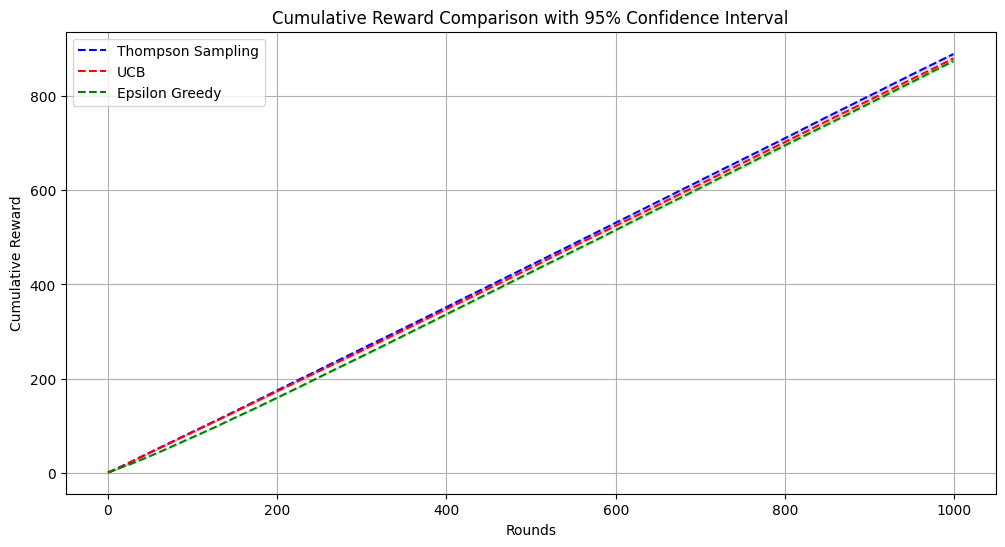

In [13]:
plot_results(results_ts, results_ucb, results_eg, "Reward")

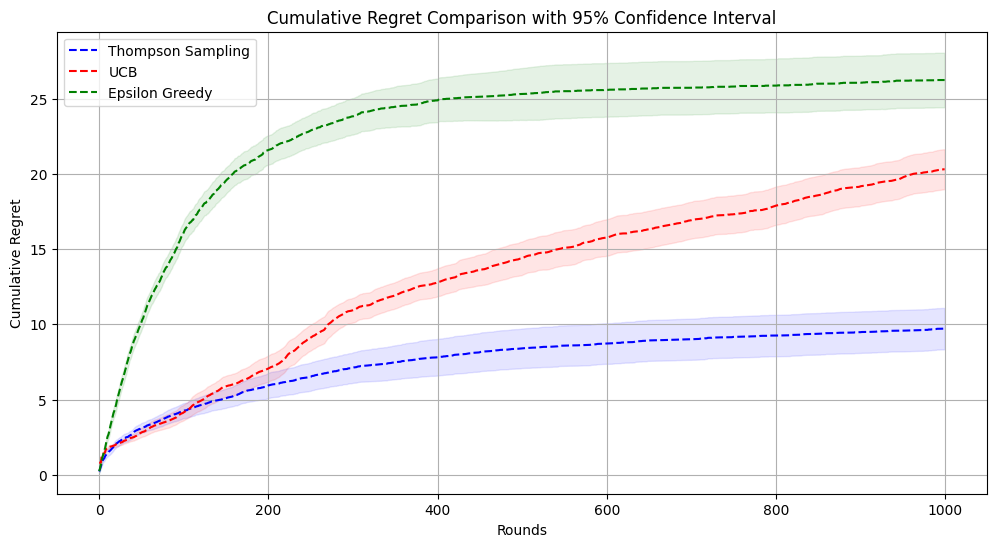

In [14]:
plot_results(results_ts, results_ucb, results_eg, "Regret")

#### Convergence Analysis

In [15]:
def calculate_convergence_round(optimal_selections, threshold=0.9, min_consistency_rounds=15):
    """
    Calculate the round at which the optimal selection rate first meets or exceeds the threshold and remains
    consistent for a specified number of rounds.
    """
    num_rounds = len(optimal_selections)
    cumulative_optimal_rate = np.cumsum(optimal_selections) / (np.arange(1, num_rounds + 1))

    for round_i in range(min_consistency_rounds, num_rounds):
        # Check if cumulative rate exceeds threshold over the past 'min_consistency_rounds'
        if np.all(cumulative_optimal_rate[round_i - min_consistency_rounds : round_i] >= threshold):
            return round_i
    return num_rounds

In [16]:
convergence_round_ts = calculate_convergence_round(results_ts['optimal_selections'], threshold=0.8)
convergence_round_ucb = calculate_convergence_round(results_ucb['optimal_selections'], threshold=0.8)
convergence_round_eg = calculate_convergence_round(results_eg['optimal_selections'], threshold=0.8)

print(f"Thompson Sampling converges at round: {convergence_round_ts}")
print(f"UCB converges at round: {convergence_round_ucb}")
print(f"Epsilon-Greedy converges at round: {convergence_round_eg}")

Thompson Sampling converges at round: 92
UCB converges at round: 197
Epsilon-Greedy converges at round: 307


## <font> Parameter analysis setup </font>


In [17]:
def analyze_parameter_impact(algorithm_class, param_values, param_name, probabilities, num_arms, num_rounds, num_trials=10):
    for value in param_values:
        kwargs = {param_name: value}
        results = simulate(algorithm_class, probabilities, num_arms, num_rounds, num_trials, **kwargs)

        plt.plot(results['rewards_mean'], label=f"{param_name} = {value}")
        plt.fill_between(np.arange(num_rounds),
                         results['rewards_mean'] - results['rewards_conf_interval'],
                         results['rewards_mean'] + results['rewards_conf_interval'], alpha=0.1)

    plt.title(f"Impact of {param_name} on Cumulative Reward")
    plt.xlabel("Round")
    plt.ylabel("Cumulative Reward")
    plt.legend()
    plt.show()

    for value in param_values:
        kwargs = {param_name: value}
        results = simulate(algorithm_class, probabilities, num_arms, num_rounds, num_trials, **kwargs)

        plt.plot(results['regrets_mean'], label=f"{param_name} = {value}")
        plt.fill_between(np.arange(num_rounds),
                         results['regrets_mean'] - results['regrets_conf_interval'],
                         results['regrets_mean'] + results['regrets_conf_interval'], alpha=0.1)

    plt.title(f"Impact of {param_name} on Cumulative Regret")
    plt.xlabel("Round")
    plt.ylabel("Cumulative Regret")
    plt.legend()
    plt.show()


### <font> Tompson Sampling Analysis </font>


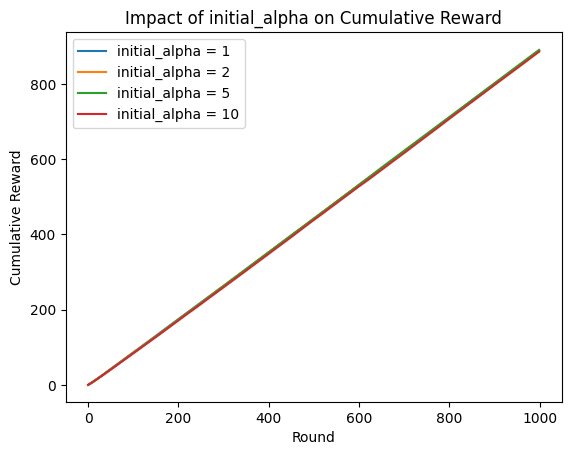

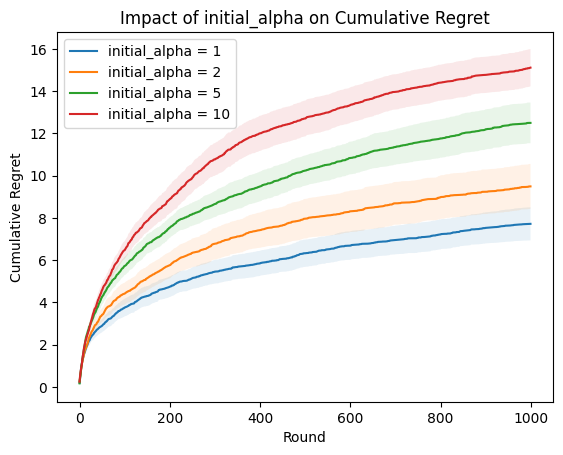

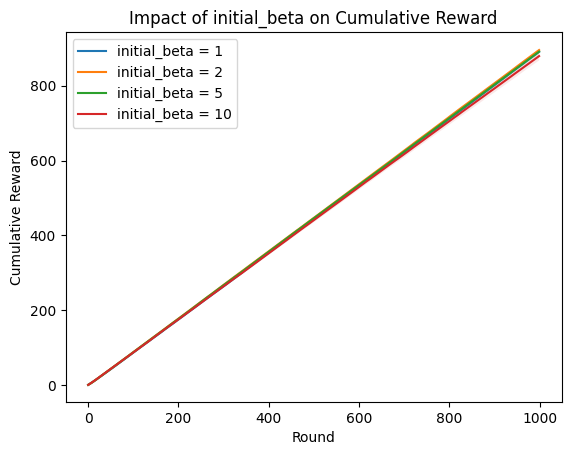

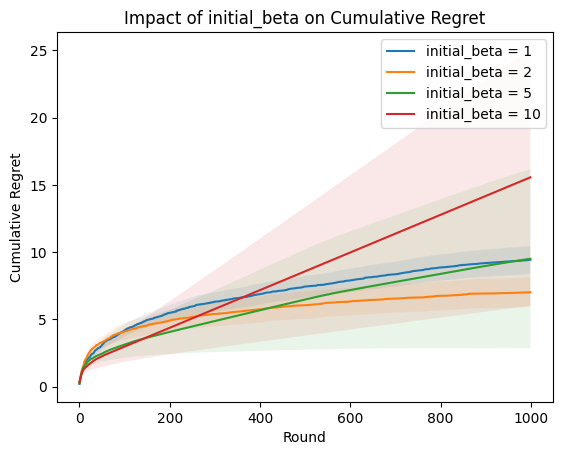

In [18]:
initial_alpha_beta_values = [1, 2, 5, 10]
analyze_parameter_impact(thompson_sampling, initial_alpha_beta_values, 'initial_alpha', probabilities, num_arms, num_rounds, num_trials)
analyze_parameter_impact(thompson_sampling, initial_alpha_beta_values, 'initial_beta', probabilities, num_arms, num_rounds, num_trials)

### <font> UCB Analysis </font>


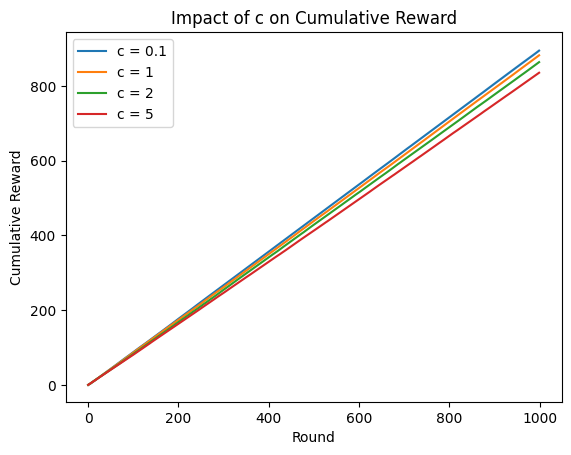

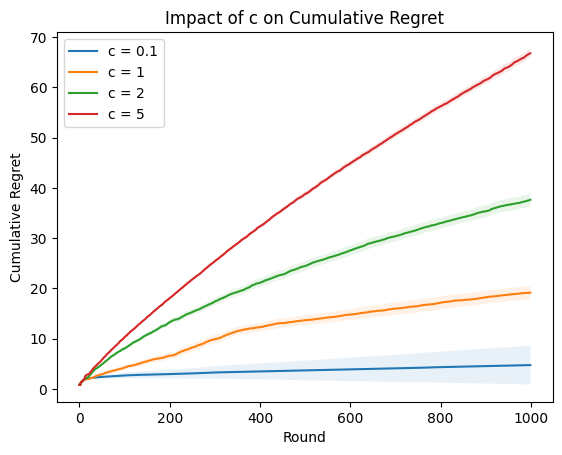

In [53]:
ucb_c_values = [0.1, 1, 2, 5]
analyze_parameter_impact(UCB, ucb_c_values, 'c', probabilities, num_arms, num_rounds, num_trials)

### <font> epsilon-greedy Analysis </font>


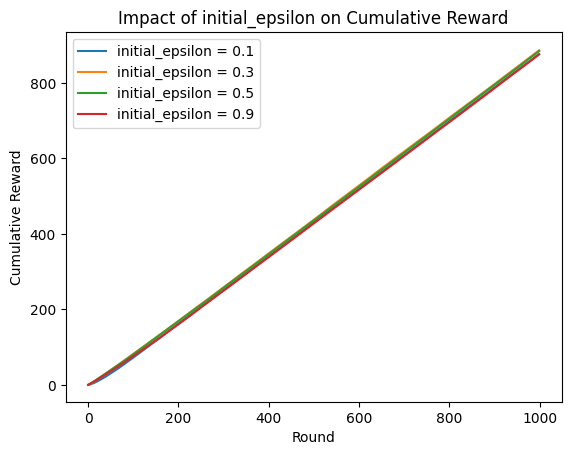

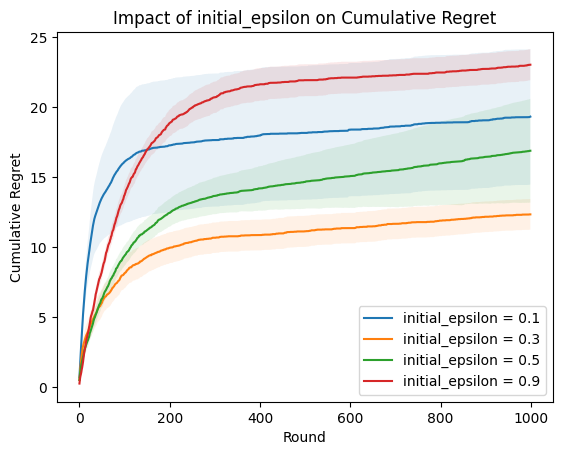

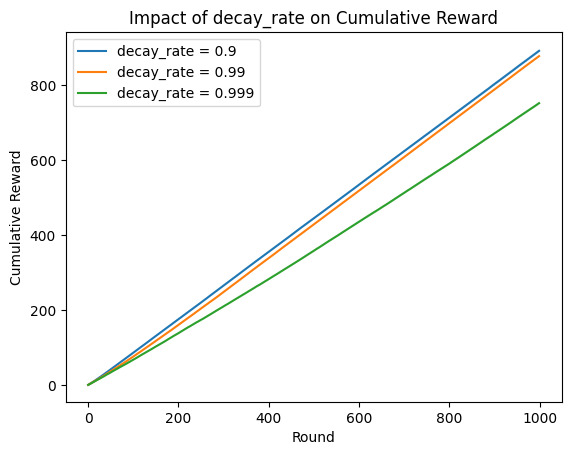

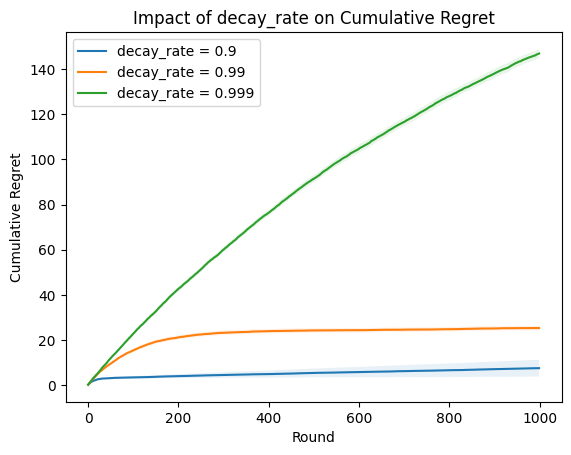

In [20]:
# Testing impact of different initial epsilon values in Epsilon-Greedy
initial_epsilon_values = [0.1, 0.3, 0.5, 0.9]
analyze_parameter_impact(epsilon_greedy, initial_epsilon_values, 'initial_epsilon', probabilities, num_arms, num_rounds, num_trials)

# Alternatively, testing decay rates
decay_rate_values = [0.9, 0.99, 0.999]
analyze_parameter_impact(epsilon_greedy, decay_rate_values, 'decay_rate', probabilities, num_arms, num_rounds, num_trials)


# <font color = lightGreen> Problem 2: 
Advertising in an Online Store  </font>

We assume that the reward is observed only after every two rounds, and then the process resets. For example, the sequence might look like: 0 (no), 1 (yes), 2 (no), ... We do not encounter situations like 0 (no), 1 (yes), 2 (yes), 3 (yes) ...( because there is always an ad shown prior to time steps 1, 2, and so on.)

In [38]:
def show_ad(ad):
    print(f"Ad: {ad}")

def observe_reward():
    return np.random.randint(2) # get 1 or 0 from user

In [39]:

def Approach1_epsilon_greedy_mdp(user_is_active, initial_epsilon=1.0, min_epsilon=0.01, decay_rate=0.99):
    ad1 = 0
    ad2 = 1
    q_value = [[0, 0], [0, 0]]  # q_values[state][action] -> rewards for transitions from state 0 or 1 with action 0 (Ad 1) or 1 (Ad 2)
    counts = [[0, 0], [0, 0]]  # counts[state][action] -> number of times each state-action pair was chosen
    state = np.random.choice([ad1, ad2])  # Initial state (randomly choose to start with Ad 1 or Ad 2)

    epsilon = initial_epsilon

    t = 0
    while(user_is_active):
        if t % 2 == 0:  # Even step: choose the first ad (no reward yet)
            if np.random.rand() < epsilon:  # Exploration
                action = np.random.choice([ad1, ad2])
            else:  # Exploitation
                action = np.argmax(q_value[state])


            show_ad(action)
            ### there no reward so we don't update
            # reward = observe_reward()
            # counts[state][action] += 1
            # alpha = 1 / (N[state][action])
            # q_value[state][action] += alpha * (reward - q_value[state][action])
            ###
            state = action



        else:  # Odd time step, show the second ad + observe the reward
            if np.random.rand() < epsilon:  # Exploration
                action = np.random.choice([ad1, ad2])
            else:  # Exploitation
                action = np.argmax(q_value[state])


            show_ad(action)
            counts[state][action] += 1
            reward = observe_reward()
            alpha = 1 / (counts[state][action])
            q_value[state][action] += alpha * (reward - q_value[state][action])

            state = action

        t += 1

        epsilon = max(min_epsilon, epsilon * decay_rate)

In [40]:
def Approach2_epsilon_greedy(user_is_active, initial_epsilon=1.0, min_epsilon=0.01, decay_rate=0.99):
    ad1 = 0
    ad2 = 1
    q_values = np.zeros(4) #Save estimated rewards for [(Ad1 -> Ad2), (Ad2 -> Ad1), (Ad1 -> Ad1), (Ad2 -> Ad2)] in q_values
    counts = np.zeros(4) # Number of trials for each sequence in counts
    sequences = [[ad1, ad2], [ad2, ad1], [ad1, ad1], [ad2, ad2]] # List of possible sequences (Actions)
    current_sequence = None
    action = None

    epsilon = initial_epsilon

    t = 0
    while(user_is_active):
        if t % 2 == 0:  # Even time step, choose a sequence  (no reward yet)
            if np.random.rand() < epsilon:  # Exploration
                action = np.random_choice([0, 1, 2, 3])
            else:  # Exploitation
                action = np.argmax(q_values)

            current_sequence = sequences[action]  # Get the chosen sequence (first and second ad)
            first_ad = current_sequence[0]  # First ad in the sequence

            show_ad(first_ad)

        else:  # Odd time step, show the second ad + observe the reward
            second_ad = current_sequence[1]
            show_ad(second_ad)

            # Observe the reward after showing the second ad
            Reward = observe_reward()

            counts[action] += 1
            alpha = 1 / counts[action]
            q_values[action] += (Reward - q_values[action]) * alpha

        t += 1

        epsilon = max(min_epsilon, epsilon * decay_rate)

In [41]:
def user_is_active():
    pass

In [42]:
def run(num_users, epsilon, approach):
    for user in range(num_users):
        if approach == 1:
            Approach1_epsilon_greedy_mdp(epsilon, user_is_active())
        elif approach == 2:
            Approach2_epsilon_greedy(epsilon, user_is_active())
        else:
            print("Invalid approach selected. Please choose 1 or 2.")

# <font color = lightGreen> Problem 3: 
Social Mobile  </font>

In [43]:
num_agents = 10
agents = range(num_agents)

In [44]:
def do_action(action):
    pass

def observe_reward():
    pass

def run_and_get_reward(action):
    do_action(action)
    return observe_reward()

def get_observed_actions(agents):
    for agent in agents:
        pass
    pass

In [45]:
def general_approach_social_mobile(user_is_active, agents, episodes, actions, imitation_weight_ = 0.5, initial_epsilon=1.0, min_epsilon=0.01, decay_rate=0.99):
    q_values = np.zeros(actions)
    counts = np.zeros(actions)
    imitation_weight = imitation_weight_
    t = 0
    epsilon = initial_epsilon

    for episode in episodes:
        while(user_is_active):
            if random() < ε: # Exploration
                action = np.random.choice(actions)
            else: # Exploitation
                action = np.argmax(q_values[action])

            do_action(action)
            reward = run_and_get_reward(action)
            alpha = 1 / counts[action]
            q_values[action] += alpha * (reward - q_values[action])

            # Observe actions of other agents
            observed_actions = get_observed_actions(agents)

            # Imitation: Update Q-values based on observed actions
            for observed_action in observed_actions:
                q_values[observed_action] += imitation_weight  * (1 - q_values[observed_action])

            t +=1
            epsilon = max(min_epsilon, epsilon * decay_rate)

    return q_values



In [46]:
def select_top_agents(score_dict, k):
    return sorted(score_dict, key=score_dict.get, reverse=True)[:k]

In [47]:
def update_scores(score_dict, observed_agents, observed_actions, q_values):
    for agent, action in zip(observed_agents, observed_actions):
        # Consistency Update: Increase score if the agent repeats an action
        if score_dict[agent]["last_action"] == action:
            score_dict[agent]["score"] += 1  # Increment for consistency
        else:
            score_dict[agent]["last_action"] = action  # Update last action

        # Quality Update: Increase score if the action matches our high-Q action
        if q_values[action] > q_values.mean():  # Compare with an average or threshold Q-value
            score_dict[agent]["score"] += 2  # Increment more for good actions

        # Diversity Update: Increase score if the agent takes an action not frequently observed
        if action not in score_dict[agent]["observed_actions"]:
            score_dict[agent]["score"] += 1  # Increment for introducing diversity
            score_dict[agent]["observed_actions"].add(action)  # Track observed actions

        # Decay Score Over Time :Reduce scores gradually if the agent is no longer being useful
        score_dict[agent]["score"] *= 0.99  # Small decay factor to allow new agents a chance


In [48]:
# Initialization for score_dict
score_dict = {agent: {"score": 0, "last_action": None, "observed_actions": set()} for agent in agents}

In [49]:
def selective_observation_social_mobile(user_is_active, agents, episodes, actions, imitation_weight_ = 0.5, initial_epsilon=1.0, min_epsilon=0.01, decay_rate=0.99, evaluation_period_ = 2, k = 5):
    q_values = np.zeros(actions)
    counts = np.zeros(actions)
    imitation_weight = imitation_weight_
    t = 0
    epsilon = initial_epsilon
    observed_agents = set()

    evaluation_period = evaluation_period_
    score_dict = {}

    for episode in episodes:
        while(user_is_active):
            if random() < ε: # Exploration
                action = np.random.choice(actions)
            else: # Exploitation
                action = np.argmax(q_values[action])

            do_action(action)
            reward = run_and_get_reward(action)
            alpha = 1 / counts[action]
            q_values[action]+= alpha * (reward - q_values[action])

            if t % evaluation_period == 0:
                observed_agents = select_top_agents(score_dict, k)

                # Observe actions of selected agents
                observed_actions = get_observed_actions(observed_agents)
                for observed_action in observed_actions:
                    q_values[observed_action] += imitation_weight  * (1 - q_values[observed_action])
                    # Update scores for each agent based on their observed consistency

                update_scores(score_dict, observed_agents, observed_actions)

            t +=1
            epsilon = max(min_epsilon, epsilon * decay_rate)

    return q_values

In [50]:
def adaptive_social_mobile(user_is_active, agents, episodes, actions, imitation_weight_ = 0.5, initial_epsilon=1.0, min_epsilon=0.01, decay_rate=0.99, evaluation_period_ = 2, k = 5):
    q_values = np.zeros(actions)
    counts = np.zeros(actions)
    imitation_weight = imitation_weight
    t = 0

    evaluation_period = evaluation_period_
    epsilon = initial_epsilon
    observed_agents = set()
    score_dict = {}

    for episode in episodes:
        while(user_is_active):
            if random() < ε: # Exploration
                action = np.random.choice(actions)
            else: # Exploitation
                action = np.argmax(q_values[action])

        reward = run_and_get_reward(action)

        if reward is not None: # Reward Phase: Update Q-value based on direct user reward
            alpha = 1/counts[action]
            q_values[action] += alpha * (reward - q_values[action])

        else:# Non-Reward Phase: Select top-performing agents for observation
            # Adjust evaluation period based on risk preference
            # Longer evaluation period for risk-averse users after negative rewards
            if R > 0.5:
                evaluation_period = max(1, evaluation_period // 2)  # More frequent evaluation for risk-seeking users
            else:
                evaluation_period = evaluation_period * 2  # Less frequent evaluation for risk-averse users

            if t % evaluation_period == 0:
                observed_agents = select_top_agents(score_dict, k)

                # Observe actions of selected agents
                observed_actions = get_observed_actions(observed_agents)
                for observed_action in observed_actions:
                    q_values[observed_action] += imitation_weight  * (1 - q_values[observed_action])
                    # Update scores for each agent based on their observed consistency

                update_scores(score_dict, observed_agents, observed_actions)

        t +=1
        epsilon = max(min_epsilon, epsilon * decay_rate)

    return q_values


In [51]:
def adaptive_social_mobile_prospectTheory(user_is_active, agents, episodes, actions, imitation_weight_ = 0.5, initial_epsilon=1.0, min_epsilon=0.01, decay_rate=0.99, evaluation_period_ = 2, k = 5, r = 0.5):
    q_values = np.zeros(actions)
    counts = np.zeros(actions)
    imitation_weight = imitation_weight
    R = r
    t = 0

    evaluation_period = evaluation_period_
    epsilon = initial_epsilon
    observed_agents = set()
    score_dict = {}

    for episode in episodes:
        while(user_is_active):
            if random() < epsilon: # Exploration
                action = np.random.choice(actions)
            else: # Exploitation
                action = np.argmax(q_values[action])

        reward = run_and_get_reward(action)

        if reward is not None: # Reward Phase: Update Q-value based on direct user reward
            alpha = 1/counts[action]
            q_values[action] += alpha * (reward - q_values[action])

            # if action is novel or less frequently chosen - Increase R if user rewards
            if counts[action] == min(counts):
                R = min(1, R + 0.05)
            else:
                R = max(0, R - 0.05)

            if R > 0.5:
                evaluation_period = max(1, base_evaluation_period // 2)  # More frequent evaluation for risk-seeking users
            else:
                evaluation_period = base_evaluation_period * 2  # Less frequent evaluation for risk-averse users

        else:# Non-Reward Phase: Select top-performing agents for observation
            # Adjust evaluation period based on risk preference
            # Longer evaluation period for risk-averse users after negative rewards
            if R > 0.5:
                evaluation_period = max(1, evaluation_period // 2)  # More frequent evaluation for risk-seeking users
            else:
                evaluation_period = evaluation_period * 2  # Less frequent evaluation for risk-averse users

            if t % evaluation_period == 0:
                observed_agents = select_top_agents(score_dict, k)

                # Observe actions of selected agents
                observed_actions = get_observed_actions(observed_agents)
                for observed_action in observed_actions:
                    q_values[observed_action] += imitation_weight  * (1 - q_values[observed_action])
                    # Update scores for each agent based on their observed consistency

                update_scores(score_dict, observed_agents, observed_actions)

        t +=1
        epsilon = max(min_epsilon, epsilon * decay_rate)

    return q_values


In [52]:
def final_social_mobile(user_is_active, agents, episodes, actions, imitation_weight_ = 0.5, initial_epsilon=1.0, min_epsilon=0.01, decay_rate=0.99, evaluation_period_ = 2, k = 5, r = 0.5):
    q_values = np.zeros(actions)
    counts = np.zeros(actions)
    imitation_weight = imitation_weight
    R = r
    t = 0
    evaluation_period = evaluation_period_
    epsilon = initial_epsilon
    observed_agents = set()
    score_dict = {}
    evaluation_period = evaluation_period_

    for episode in episodes:
        while(user_is_active):
            if random() < epsilon: # Exploration
                action = np.random.choice(actions)
            else: # Exploitation
                action = np.argmax(q_values[action])

            reward = run_and_get_reward(action)

            if reward is not None: # Reward Phase: Update Q-value based on direct user reward
                alpha = 1/counts[action]
                if reward > 0:
                    # Positive Reward Phase:
                    q_values[action] += alpha * (reward - q_values[action])

                    # if action is novel or less frequently chosen - Increase R if user rewards
                    if counts[action] == min(counts):
                        R = min(1.0, R + 0.05)
                    else:
                        R = max(0.0, R - 0.05)

                elif reward < 0:
                    # Negative Reward Phase:
                    q_values[action] += alpha * (reward - q_values[action])

                    # Update risk preference (R) based on negative outcome
                    if R > 0.5:
                        # Risk-seeking users tolerate negative rewards
                        R = max(0.0, R - 0.05)  # Slight reduction in risk preference
                    else:
                        # Risk-averse users strongly avoid negative outcomes
                        R = max(0.0, R - 0.1)  # Strong reduction in risk preference

            else:# Non-Reward Phase: Select top-performing agents for observation
                # Adjust evaluation period based on risk preference
                # Longer evaluation period for risk-averse users after negative rewards
                if R > 0.5:
                    evaluation_period = max(1, evaluation_period // 2)  # More frequent evaluation for risk-seeking users
                else:
                    evaluation_period = evaluation_period * 2  # Less frequent evaluation for risk-averse users

                # Select top-performing agents for observation periodically
                if t % evaluation_period == 0:
                    observed_agents = select_top_agents(score_dict, k)

                    # Observe actions of selected agents
                    observed_actions = get_observed_actions(observed_agents)
                    for observed_action in observed_actions:
                        q_values[observed_action] += imitation_weight  * (1 - q_values[observed_action])

                    # Update scores for each agent based on their observed consistency
                    update_scores(score_dict, observed_agents, observed_actions)

        t += 1
        epsilon = max(min_epsilon, epsilon * decay_rate)

    return q_values